In [1]:
"""
making more figures
"""

'\nmaking more figures\n'

In [58]:
import os
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt

In [59]:
import implantation_functions as imp
import review_findings_functions as rff

In [60]:
import ztffields
import pandas as pd

In [4]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [2]:
!ls "/lustre/lrspec/ZTF_data/training_aug24/stamps_no_trans/images/" | wc -l

1148


In [4]:
!ls "/lustre/lrspec/ZTF_data/training_aug24/stamps_pos_trans_2/images/" | wc -l

1148


In [7]:
!ls "/lustre/lrspec/ZTF_data/training_aug24/stamps_neg_trans_2/images" | wc -l

1148


In [8]:
!ls "/lustre/lrspec/ZTF_data/training_aug24/stamps_background/images/" | wc -l

1148


In [203]:
fpath_cr = "/lustre/lrspec/ZTF_data/training_aug24/stamps_cr/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

for i, file in enumerate(os.listdir(fpath_cr)):
    image_filename = os.fsdecode(file)
    image_filename_full = fpath_cr + image_filename
    print(image_filename)
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    print(np.shape(trans))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_cr_stamps = trans
    else:
        all_cr_stamps = np.concatenate((all_cr_stamps, trans_arr), axis=0)

cr_1017.npy
(150, 20, 20)
cr_1014.npy
(150, 20, 20)
cr_0820.npy
(150, 20, 20)
cr_1020.npy
(150, 20, 20)


In [15]:
# so that's 600

In [17]:
!ls "/lustre/lrspec/ZTF_data/training_aug24/stamps_pos_trans_2/info/" | wc -l

1148


In [6]:
file = "/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c03_x.fits.fz"

In [7]:
hdul = fits.open(file)
file1_array = hdul[1].data

Text(370, 50, '308 pixels=1 second ')

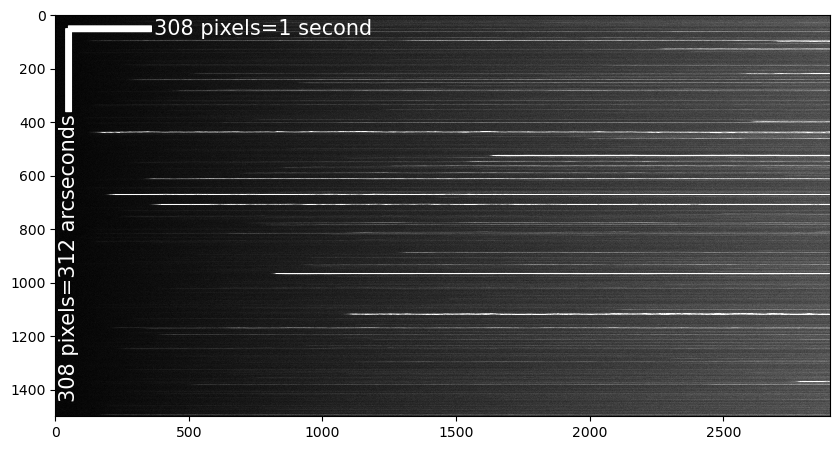

In [145]:
# plt.rcParams["figure.figsize"] = (10, 8)
norm = (file1_array - np.min(file1_array)) / (
    np.max(file1_array) - np.min(file1_array)
)  # norm
log_image = np.log1p(norm)
gamma = 0.5
gamma_image = np.power(norm, gamma)
plt.imshow(log_image.T, vmin=0, vmax=0.15)
plt.ylim(1500, 0)
plt.xlim(0, 2900)
# plt.plot(np.linspace(50,350,300), np.full(300,50), color='white')
# plt.plot(np.full(300,50), np.linspace(50,350,300), color='white')
# plt.annotate('300 pixels \n=975 milliseconds ', xy=(360, 150), xytext=(360, 150), color='white', fontsize=15, zorder=10)
# plt.annotate('300 pixels \n=303 arcseconds', xy=(15, 500), xytext=(15, 500), color='white',fontsize=15, zorder=10)
# plt.plot(np.linspace(50,358,308), np.full(308,50), color='red')
# plt.plot(np.full(308,50), np.linspace(50,358,308), color='white')

# textcoords=dict('offset points'=12),
# plt.annotate('308 pixels=312 arcseconds', xy=(15, 370), xytext=(15, 370),
#              color='white',fontsize=15, ha='center', va='top', zorder=10, rotation=90)
plt.annotate(
    "308 pixels=312 arcseconds",
    xy=(50, 50),
    xytext=(50, 370),  # make it 358 eventually
    arrowprops=dict(
        facecolor="white",
        edgecolor="white",
        shrink=0.0,
        headlength=0.001,
        headwidth=0.001,
    ),
    color="white",
    fontsize=15,
    ha="center",
    va="top",
    rotation=90,
    zorder=10,
)

plt.annotate(
    "308 pixels=1 second ",
    xy=(50, 50),
    xytext=(370, 50),  # make it 358 eventually
    arrowprops=dict(
        facecolor="white",
        edgecolor="white",
        shrink=0.0,
        headlength=0.001,
        headwidth=0.001,
    ),
    color="white",
    fontsize=15,
    va="center",
    zorder=1,
)

(1500.0, 0.0)

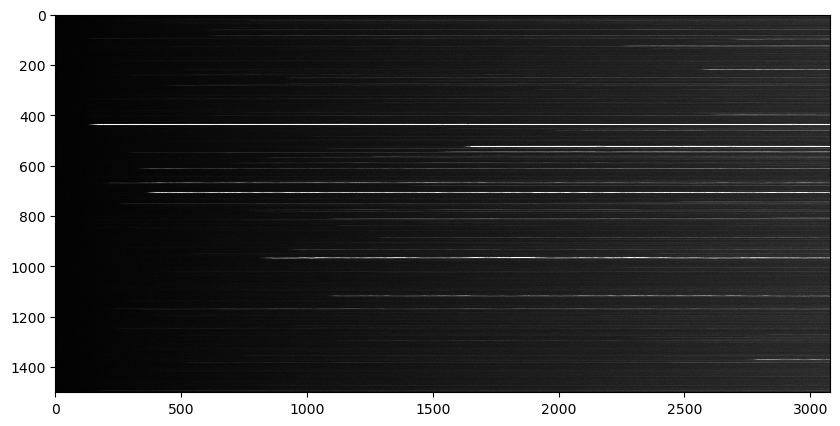

In [141]:
norm = (file1_array - np.min(file1_array)) / (
    np.max(file1_array) - np.min(file1_array)
)  # norm
log_image = np.log1p(norm)
gamma = 0.5
gamma_image = np.power(norm, gamma)
plt.imshow(log_image.T, vmin=0, vmax=0.3)
plt.ylim(1500, 0)
# plt.xlim(0,2000)
# plt.tick_params(off)

(0.0, 2500.0)

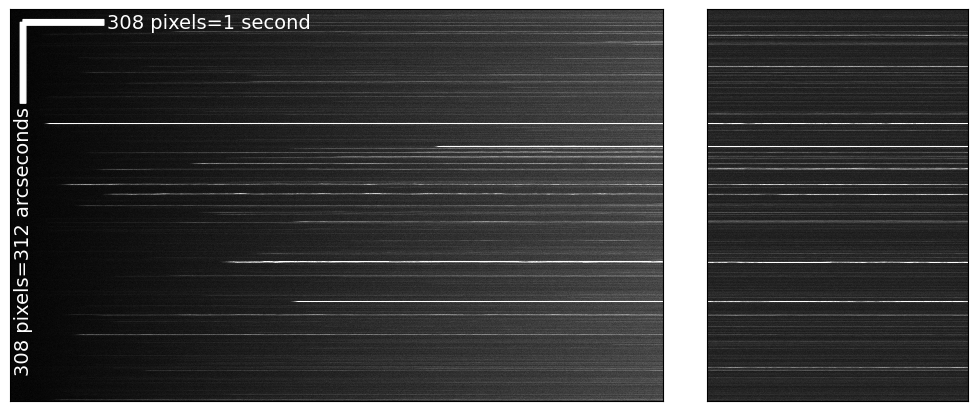

In [197]:
file = "/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c03_x.fits.fz"
hdul = fits.open(file)
file1_array = hdul[1].data

# fig, ax = plt.subplots(1, 2, figsize=(20, 10))

gs_kw = dict(width_ratios=[2, 1], height_ratios=[1])
fig, ax = plt.subplot_mosaic(
    [[0, 1]], figsize=(10, 4), gridspec_kw=gs_kw, layout="constrained"
)


norm = (file1_array - np.min(file1_array)) / (
    np.max(file1_array) - np.min(file1_array)
)  # norm
log_image = np.log1p(norm)
ax[0].imshow(log_image.T, vmin=0, vmax=0.15)

# plt.plot(np.linspace(50,350,300), np.full(300,50), color='white')
# plt.plot(np.full(300,50), np.linspace(50,350,300), color='white')
# plt.annotate('300 pixels \n=975 milliseconds ', xy=(360, 150), xytext=(360, 150), color='white', fontsize=15, zorder=10)
# plt.annotate('300 pixels \n=303 arcseconds', xy=(15, 500), xytext=(15, 500), color='white',fontsize=15, zorder=10)
# plt.plot(np.linspace(50,358,308), np.full(308,50), color='red')
# plt.plot(np.full(308,50), np.linspace(50,358,308), color='white')

# textcoords=dict('offset points'=12),
# plt.annotate('308 pixels=312 arcseconds', xy=(15, 370), xytext=(15, 370),
#              color='white',fontsize=15, ha='center', va='top', zorder=10, rotation=90)
ax[0].annotate(
    "308 pixels=312 arcseconds",
    xy=(50, 50),
    xytext=(50, 370),  # make it 358 eventually
    arrowprops=dict(
        facecolor="white",
        edgecolor="white",
        shrink=0.0,
        headlength=0.001,
        headwidth=0.001,
    ),
    color="white",
    fontsize=14,
    ha="center",
    va="top",
    rotation=90,
    zorder=10,
)

ax[0].annotate(
    "308 pixels=1 second ",
    xy=(50, 50),
    xytext=(370, 50),  # make it 358 eventually
    arrowprops=dict(
        facecolor="white",
        edgecolor="white",
        shrink=0.0,
        headlength=0.001,
        headwidth=0.001,
    ),
    color="white",
    fontsize=14,
    va="center",
    zorder=1,
)

file2 = (
    "/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c03_x_0029.fits.fz"
)
hdul2 = fits.open(file2)
file1_array2 = hdul2[1].data

norm2 = (file1_array2 - np.min(file1_array2)) / (
    np.max(file1_array2) - np.min(file1_array2)
)  # norm
log_image2 = np.log1p(norm2)

ax[1].imshow(log_image2.T, vmin=0, vmax=0.25)
ax[1].set_ylim(1500, 0)
ax[1].set_xlim(0, 1000)
ax[0].set_xticks([])
ax[1].set_xticks([])
ax[0].set_yticks([])
ax[1].set_yticks([])

ax[0].set_ylim(1500, 0)
ax[0].set_xlim(0, 2500)

(0.0, 500.0)

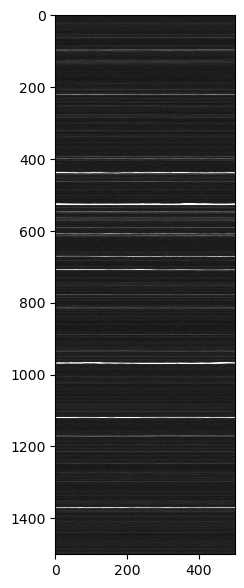

In [5]:
file = (
    "/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c03_x_0029.fits.fz"
)
hdul = fits.open(file)
file1_array = hdul[1].data

norm = (file1_array - np.min(file1_array)) / (
    np.max(file1_array) - np.min(file1_array)
)  # norm
log_image = np.log1p(norm)
gamma = 0.5
gamma_image = np.power(norm, gamma)
plt.imshow(log_image.T, vmin=0, vmax=0.3)
plt.ylim(1500, 0)
plt.xlim(0, 500)

In [47]:
model = keras.models.load_model("/home/3155/CNN_sept2")

visualkeras.layered_view(model).show()  # display using your system viewer
# visualkeras.layered_view(model, to_file='output.png') # write to disk
# visualkeras.layered_view(model, to_file='output.png').show() # write and show

# visualkeras.layered_view(model)

/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/visualkeras/layered.py:86: UserWarning: The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.
  warnings.warn("The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.")

(eog:22965): dconf-CRITICAL **: 16:29:45.047: unable to create directory '/run/user/3155/dconf': Permission denied.  dconf will not work properly.

(eog:22965): dconf-CRITICAL **: 16:29:45.047: unable to create directory '/run/user/3155/dconf': Permission denied.  dconf will not work properly.

(eog:22965): dconf-CRITICAL **: 16:29:45.048: unable to create directory '/run/user/3155/dconf': Permission denied.  dconf will not work properly.

(eog:22965): Gtk-WARNING **: 16:29:45.048: cannot open display: 


START /usr/bin/eog "/tmp/tmpu6mq8djb.PNG"


In [48]:
model.summary()

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 20, 20, 16)        416       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 10, 10, 16)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 10, 10, 32)        4640      
                                                                 
 conv2d_2 (Conv2D)           (None, 10, 10, 32)        9248      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 5, 5, 32)         0         
 2D)                                                             
                                                                 
 flatten (Flatten)           (None, 800)              

In [ ]:
# okay so i need for each of them a full image
# ...or maybe just fuller than 2 seconds
# but i did not implant them in that
# so i guess i can do that now...

(960.0, 980.0)

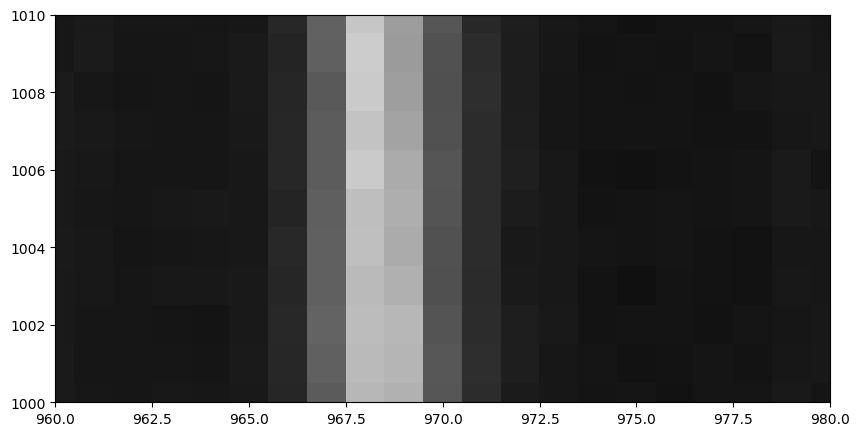

In [13]:
plt.imshow(np.sqrt(file1_array))
plt.ylim(1000, 1010)
plt.xlim(960, 980)

In [9]:
file2 = (
    "/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c03_x_0029.fits.fz"
)
hdul2 = fits.open(file2)
file1_array2 = hdul2[1].data

In [10]:
imp_pos = imp.implant_transient_full_image(
    file1_array2, streak_x_val=968, center_value_y=1000, intensity=1.3, sigma=5
)

[968, 969, 970, 967]


(960.0, 980.0)

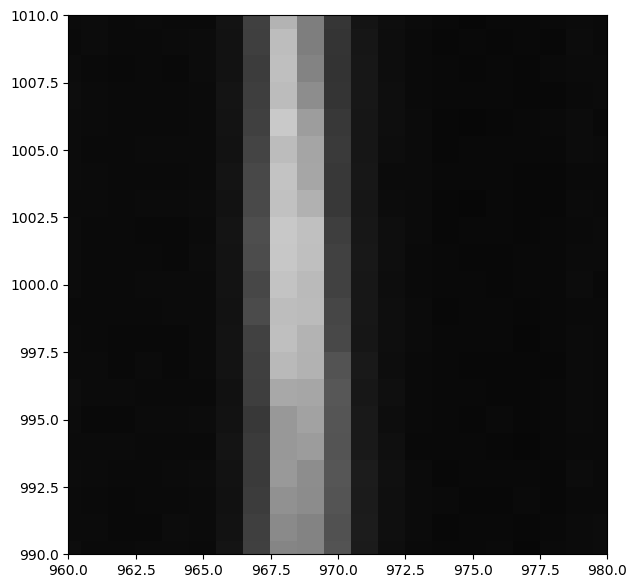

In [54]:
plt.imshow(imp_pos)
plt.ylim(990, 1010)
plt.xlim(960, 980)

In [232]:
def plot_time_series_zoom_implant(image, row, col):
    """
    zoom in
    this plots a time series from a dataframe, making it and easy to diagnose
    inputs: dataframe, index, directory where the images live
    outputs: none, but plots.
    specifications: both poisson and stdv error, no normalization
    background is subtracted
    plots all the other transients also
    returns a dataframe missing the rows that were plotted
    """
    # index=2
    # df=df_0820_short
    # direcname = "0820"
    wid = 0

    file1_array = image
    norm = (file1_array - np.min(file1_array)) / (
        np.max(file1_array) - np.min(file1_array)
    )  # norm
    image = norm
    gaussianed_image = image
    plt.rcParams["figure.figsize"] = (10, 7)
    plt.rcParams["image.interpolation"] = "nearest"
    plt.rcParams["image.cmap"] = "gist_gray"
    # plt.imshow(norm)
    # plt.xlim(1070,1170)
    # plt.ylim(100,120)

    column = int(col)

    # note: the scatter plots are shifted in the positive x direction by wid,
    # so that they line up with the images

    gs_kw = dict(width_ratios=[2, 1], height_ratios=[1, 1])
    fig, axd = plt.subplot_mosaic(
        [["upper left", "upper mid"], ["lower left", "lower mid"]],
        gridspec_kw=gs_kw,
        figsize=(8, 3.5),
        layout="constrained",
    )

    # column_indices = [967, 968, 969, 970]
    tot = rff.get_tot_streak(image, row, tracking=True)

    # sqrt = np.sqrt(tot)

    axd["lower left"].scatter(
        np.arange(len(tot)), tot, color="black", marker=".", alpha=0.5, zorder=10
    )
    # axd['lower left'].set_ylim(0, 1499)
    # axd['lower mid'].set_ylim(0, 1499)

    axd["upper left"].imshow(np.sqrt(gaussianed_image).T, aspect=20, cmap="gist_gray")
    axd["upper left"].set_ylim(row - 10, row + 10)
    axd["upper left"].set_xlim(0, 2000)

    axd["upper left"].set_xticklabels([])
    axd["upper left"].set_yticklabels([])
    axd["upper left"].set_yticks([])
    axd["upper left"].set_xticks([])

    # axd['lower left'].set_xticks(np.arange(0, len(image[:, column]), 500))
    # axd['lower left'].set_xticklabels(np.round(np.arange(0, len(image[:, column])*10/6000, 500*10/6000)), fontsize=15)
    axd["lower left"].set_xticks(
        np.linspace(0, 3080, 11),
        labels=np.linspace(0, 10, 11, dtype="int"),
        fontsize=15,
    )

    axd["lower left"].set_xlim(0, len(image[:, column]))
    axd["lower left"].set_xlabel("Time (seconds)", fontsize=20)
    axd["lower left"].set_ylabel("Relative Flux", fontsize=14)
    axd["upper left"].set_ylabel("Image", fontsize=14)

    axd["upper mid"].imshow(np.sqrt(gaussianed_image).T, aspect=0.4, cmap="gist_gray")
    axd["upper mid"].set_xlim(column - 10, column + 10)
    axd["upper mid"].set_ylim(row - 10, row + 10)

    axd["lower mid"].set_xlim(col - 10, col + 10)
    axd["lower mid"].set_xticks(
        np.linspace(col - 8, col + 8, 3),
        labels=np.linspace((col - 8) * 10 / 3, (col + 8) * 10 / 3, 3, dtype="int"),
        fontsize=15,
    )
    axd["upper mid"].set_axis_off()
    axd["lower mid"].set_yticks([])
    # axd['lower mid'].set_xticks(np.linspace(row-30,row+30, 3))
    axd["lower mid"].set_xlabel("Time (ms)", fontsize=20)

    axd["lower mid"].scatter(np.arange(len(tot)), tot, color="black", alpha=0.5)
    # axd['lower left'].legend([" ","Poisson err.", "Stdv err."])
    axd["lower left"].legend()
    axd["lower left"].set_yticks([])

    ys = np.linspace(0, len(tot) - 1, 100000)

    #     (ys = np.linspace(0,image.shape[0]-1,image.shape[0]),
    #                                   M = center_value_y, sig = sigma, A = intensity, original_values = imagenobackground[:,i])

    gaus = imp.gaussian_event(
        ys,
        M=1000 * (len(tot) / 100000),
        sig=5 * (len(tot) / 100000),
        A=1.3,
        original_values=np.full(len(ys), np.average(tot)),
    )

    axd["lower mid"].plot(gaus, label="Gaussian function")
    axd["lower left"].plot(gaus, alpha=0.5, label="Gaussian Function")
    axd["lower left"].legend(fontsize=14)
    fig.suptitle("Brightening Training Implantation", fontsize=30)
    plt.show()
    plt.close()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


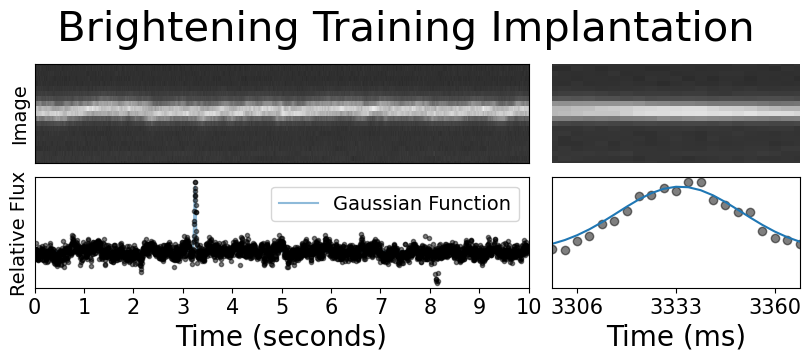

In [233]:
plot_time_series_zoom_implant(imp_pos, 968, 1000)
# imp_pos = imp.implant_transient_full_image(file1_array, streak_x_val=968, center_value_y=1000, intensity=4, sigma=5)

In [17]:
import importlib

In [18]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/review_findings_functions.py'>

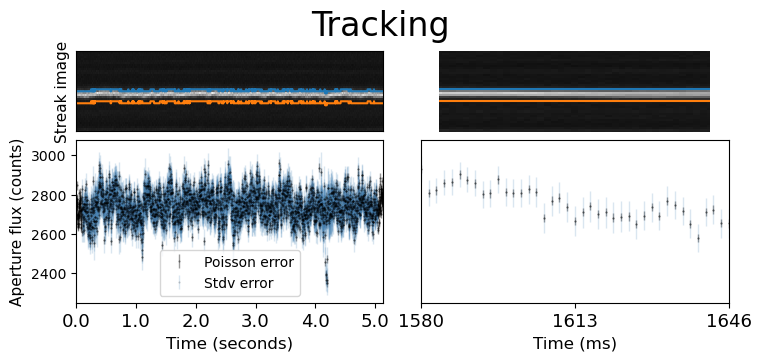

In [57]:
plot_tracking_options_implant(file1_array2, 968, 1000, "Tracking")

In [54]:
def plot_tracking_options_implant(image, row, col, title):
    """
    this plots a time series and image from a dataframe,
    showing which pixels are included
    inputs: dataframe, index, directory where the images live
    aperture is 2*half_aperture+1
    tracking can be True (tracks with brightest pixel)
    or False (constant streak center pixel)
    outputs: none, but plots.
    NOTE: now uses loc intead of iloc, so it corresponds to the actual index!!

    """
    half_aperture = 2
    tracking = True
    # wideval = 5
    # index=2
    # df=df_0820_short
    # direcname = "0820"
    wid = 0
    file1_array = image
    # norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array)) #norm
    # image = norm
    gaussianed_image = image
    plt.rcParams["figure.figsize"] = (10, 7)
    plt.rcParams["image.interpolation"] = "nearest"
    plt.rcParams["image.cmap"] = "gist_gray"
    # plt.imshow(norm)
    # plt.xlim(1070,1170)
    # plt.ylim(100,120)

    # plt.imshow(norm)
    # plt.xlim(1070,1170)
    # plt.ylim(100,120)

    column = int(col) - 30

    # note: the scatter plots are shifted in the positive x direction by wid,
    # so that they line up with the images

    gs_kw = dict(width_ratios=[2, 2], height_ratios=[1, 2])
    fig, axd = plt.subplot_mosaic(
        [["upper left", "upper mid"], ["lower left", "lower mid"]],
        gridspec_kw=gs_kw,
        figsize=(7.5, 3.5),
        layout="constrained",
    )

    background = rff.get_image_background(image)

    imagenobackground = image - np.full(np.shape(image), background)

    tot, maxcols = rff.get_tot_streak(image, row, col)

    sqrt = np.sqrt(tot / 6.2)  # 6.2 electrons per photon
    # fluxerr = np.divide(sqrt, len(column_indices))
    fluxerr = sqrt
    streakavg = tot  # i don't use this any more

    stderr = np.zeros(len(tot))
    for i in range(len(stderr)):
        if i > 60 and i < (len(stderr) - 60):
            arr = np.concatenate((tot[i - 60 : i - 10], tot[i + 10 : i + 60]))
            stderr[i] = np.std(arr)

    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="black",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.4,
        label="Poisson error",
    )

    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="SteelBlue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.2,
        label="Stdv error",
    )

    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="black",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.4,
    )

    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="SteelBlue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.2,
    )

    #     axd['lower left'].fill_between(np.arange(len(streakavg)), tot+fluxerr/2, tot-fluxerr/2,
    #                                    alpha=.5, label="Poisson error")
    #                 # color="black", ecolor='blue', elinewidth=1,linestyle='none',
    #                 # marker=".", markersize=1, alpha=.5, label="Poisson error")

    #     axd['lower left'].fill_between(np.arange(len(streakavg)), tot+stderr/2, tot-stderr/2,
    #                                    alpha=.3, label="Stdv error")
    # axd['lower left'].fill_between(np.arange(len(streakavg)), tot, yerr=stderr,
    #                 color="black", ecolor='green', elinewidth=1,linestyle='none',
    #                 marker=".", markersize=1, alpha=.5, label="Stdv error")

    axd["upper left"].imshow(np.sqrt(image).T, aspect=20, cmap="gist_gray")
    axd["upper left"].set_ylim(column - 20, column + 20)

    axd["upper left"].set_xticklabels([])
    axd["upper left"].set_yticklabels([])
    axd["upper left"].set_yticks([])
    axd["upper left"].set_xticks([])

    # axd['lower left'].set_xti3cks(np.linspace(0, len(image[:, column]), 6))

    # axd['lower left'].set_xticklabels(np.round(np.linspace(0, len(image[:, column])*10/6000, 6*10/6000)), fontsize=12)
    axd["lower left"].set_xticks(np.linspace(0, 3000, 6))
    axd["lower left"].set_xticklabels(np.round(np.linspace(0, 5, 6)), fontsize=13)

    axd["lower left"].set_xlim(0, len(image[:, column]))
    axd["lower left"].set_xlabel("Time (seconds)", fontsize=12)
    axd["lower left"].set_ylabel("Aperture flux (counts)", fontsize=11)
    axd["upper left"].set_ylabel("Streak image", fontsize=11)

    axd["upper mid"].imshow(np.sqrt(image).T, aspect=0.3, cmap="gist_gray")
    axd["upper mid"].set_xlim(row - 20, row + 20)
    axd["upper mid"].set_ylim(column - 20, column + 20)

    # axd['lower mid'].set_xlim(row-30,row+30)
    axd["lower mid"].set_xlim(row - 20, row + 20)
    # axd['lower mid'].set_xticks(np.linspace(row-20,row+20, 3))
    axd["lower mid"].set_xticks(
        np.linspace(row - 20, row + 20, 3),
        labels=np.linspace((row - 20) * 10 / 6, (row + 20) * 10 / 6, 3, dtype="int"),
        fontsize=13,
    )

    axd["upper mid"].set_axis_off()
    axd["lower mid"].set_yticks([])
    # axd['lower mid'].set_xticks(np.linspace(row-30,row+30, 3))
    axd["lower mid"].set_xlabel("Time (ms)", fontsize=12)

    # axd['lower left'].legend([" ","Poisson err.", "Stdv err."])
    axd["lower left"].legend()
    if title == None:
        fig.suptitle("Possible Transient # " + str(index), fontsize=24)
    else:
        fig.suptitle(title, fontsize=24)

    axd["upper left"].plot(np.arange(len(streakavg)), maxcols + half_aperture)
    axd["upper left"].plot(np.arange(len(streakavg)), maxcols - half_aperture - 2)
    axd["upper mid"].plot(np.arange(len(streakavg)), maxcols + half_aperture)
    axd["upper mid"].plot(np.arange(len(streakavg)), maxcols - half_aperture - 2)

    plt.show()
    plt.close()

In [83]:
?rff.get_tot_streak

Signature: rff.get_tot_streak(image, col, tracking, half_aperture=2)
Docstring:     
File:      ~/review_findings_functions.py
Type:      function

In [199]:
def normalize(file1_array):
    return (file1_array - np.min(file1_array)) / (
        np.max(file1_array) - np.min(file1_array)
    )  # norm

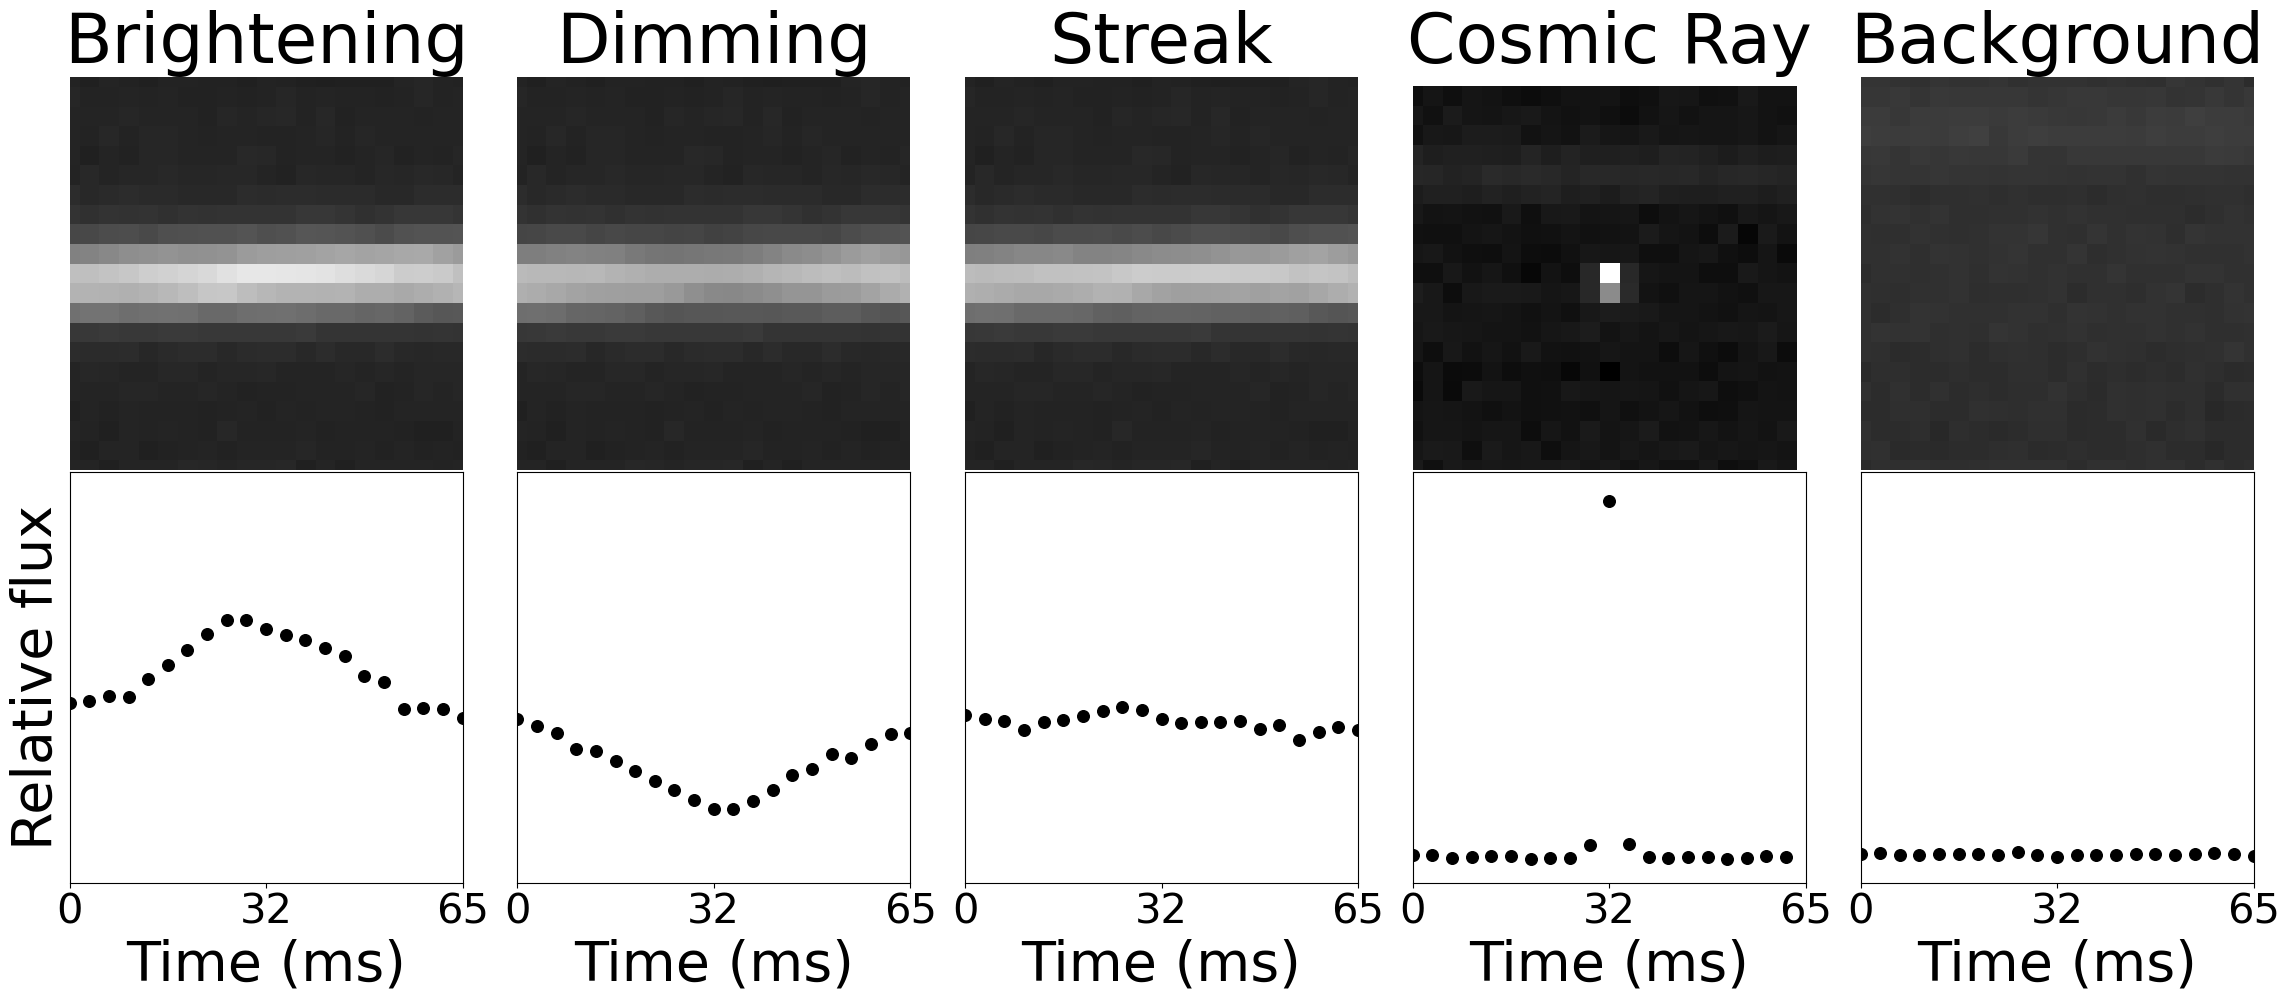

In [207]:
fig, axs = plt.subplots(2, 5, figsize=(23, 10))

axs[0, 0].set_title("Brightening", fontsize=50)
axs[0, 0].imshow(np.sqrt(normalize(imp_pos)).T, aspect=1, cmap="gist_gray")

row = 968
column = 1000
axs[0, 0].set_xlim(column - 10, column + 10)
axs[0, 0].set_ylim(row - 10, row + 10)

toplot = rff.get_tot_streak(normalize(imp_pos), row, tracking=False)

axs[1, 0].scatter(np.arange(len(toplot)), toplot, s=70, color="black")
axs[1, 0].set_xlim(column - 10, column + 10)
axs[1, 0].set_xticks(
    np.linspace(column - 10, column + 10, 3),
    labels=np.linspace(0, 65, 3, dtype="int"),
    fontsize=30,
)


axs[0, 1].set_title("Dimming", fontsize=50)
axs[0, 1].imshow(np.sqrt(normalize(imp_neg)).T, aspect=1, cmap="gist_gray")

row = 968
column = 1000
axs[0, 1].set_xlim(column - 10, column + 10)
axs[0, 1].set_ylim(row - 10, row + 10)

toplot = rff.get_tot_streak(normalize(imp_neg), row, tracking=False)

axs[1, 1].scatter(np.arange(len(toplot)), toplot, s=70, color="black")
axs[1, 1].set_xlim(column - 10, column + 10)
axs[1, 1].set_xticks(
    np.linspace(column - 10, column + 10, 3),
    labels=np.linspace(0, 65, 3, dtype="int"),
    fontsize=30,
)


axs[0, 2].set_title("Streak", fontsize=50)
axs[0, 2].imshow(np.sqrt(normalize(file1_array)).T, aspect=1, cmap="gist_gray")

row = 968
column = 1000
axs[0, 2].set_xlim(column - 10, column + 10)
axs[0, 2].set_ylim(row - 10, row + 10)

toplot = rff.get_tot_streak(normalize(file1_array), row, tracking=False)

axs[1, 2].scatter(np.arange(len(toplot)), toplot, s=70, color="black")
axs[1, 2].set_xlim(column - 10, column + 10)
axs[1, 2].set_xticks(
    np.linspace(column - 10, column + 10, 3),
    labels=np.linspace(0, 65, 3, dtype="int"),
    fontsize=30,
)


axs[0, 3].set_title("Cosmic Ray", fontsize=50)
axs[0, 3].imshow(np.sqrt(normalize(all_cr_stamps[0])).T, aspect=1, cmap="gist_gray")

# plot_time_series_zoom_implant(all_cr_stamps[0],  10, 10, title = "Cosmic Ray")
row = 10
column = 10
axs[0, 3].set_xlim(column - 10, column + 10)
axs[0, 3].set_ylim(row - 10, row + 10)

# toplot = rff.get_tot_streak(all_cr_stamps[0], 10, tracking=False, half_aperture=1)

axs[1, 3].scatter(
    np.arange(len(all_cr_stamps[0])),
    np.sum(all_cr_stamps[0][:, 8:12], axis=1),
    s=70,
    color="black",
)
axs[1, 3].set_xlim(column - 10, column + 10)
axs[1, 3].set_xticks(
    np.linspace(column - 10, column + 10, 3),
    labels=np.linspace(0, 65, 3, dtype="int"),
    fontsize=30,
)


axs[0, 4].set_title("Background", fontsize=50)
axs[0, 4].imshow(np.sqrt(normalize(file1_array2)).T, aspect=1, cmap="gist_gray")

row = 1000
column = 98
axs[0, 4].set_xlim(column - 10, column + 10)
axs[0, 4].set_ylim(row - 10, row + 10)

toplot = rff.get_tot_streak(normalize(file1_array2), row, tracking=False)

axs[1, 4].scatter(np.arange(len(toplot)), toplot + 0.6, s=70, color="black")
axs[1, 4].set_xlim(column - 10, column + 10)
axs[1, 4].set_xticks(
    np.linspace(column - 10, column + 10, 3),
    labels=np.linspace(0, 65, 3, dtype="int"),
    fontsize=30,
)

# plot_time_series_zoom_implant(file1_array,  1000, 98, title = "Background")

axs[1, 0].set_ylabel("Relative flux", fontsize=40)

for ax in axs[0]:
    ax.set_axis_off()
for ax in axs[1]:
    ax.set_yticks([])
    # ax.set_xticks(np.linspace(column-10,column+10, 3), labels = np.linspace(0,33.3, 3, dtype='int'), fontsize=30)
    ax.set_xlabel("Time (ms)", fontsize=40)
    # ax.set_aspect(20)
    ax.set_ylim(0.5, 2)

axs[1, 3].set_ylim(400, 3300)
plt.tight_layout()

In [215]:
imp_neg = imp.implant_transient_full_image(
    file1_array2, streak_x_val=968, center_value_y=1000, intensity=0.7, sigma=4
)

[968, 969, 970, 967]


In [294]:
loss = np.load("/home/3155/sept3_loss_history.npy")
val_loss = np.load("/home/3155/sept3_val_loss_history.npy")
accuracy = np.load("/home/3155/sept3_accuracy_history.npy")
val_accuracy = np.load("/home/3155/sept3_val_accuracy_history.npy")

In [311]:
import matplotlib.ticker as ticker

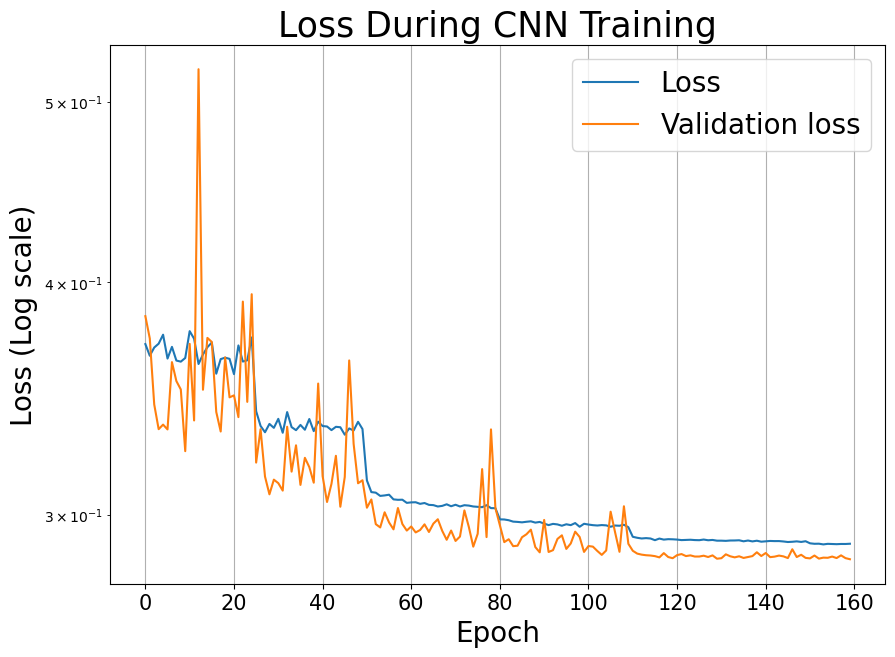

In [326]:
plt.plot(loss)
plt.plot(val_loss)
plt.yscale("log")
plt.legend(["Loss", "Validation loss"], fontsize=20)
plt.xlabel("Epoch", fontsize=20)
plt.ylabel("Loss (Log scale)", fontsize=20)
plt.title("Loss During CNN Training", fontsize=25)
plt.xticks(fontsize=15)
# plt.yticks(fontsize=25)

# plt.tick_params(axis='both', which='major', labelsize=15)

# plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f"{y:.1e}"))
# plt.yticks(fontsize=15)  # Adjust font size of y-ticks
plt.yticks(ticks=[], labels=None)  # Adjust font size of y-ticks

# plt.xlim(0,45)
plt.grid()
# plt.xlim(50,90)
# plt.ylim(.25, .35)

# plt.savefig("/home/3155/CNN_best_overfit_longer_200_training_3_outputs/loss_short")

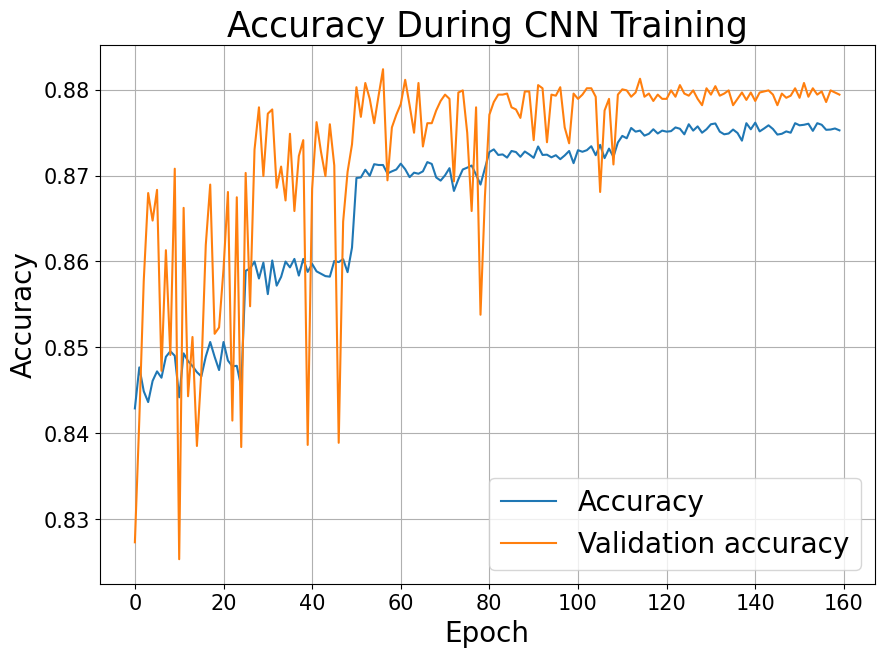

In [327]:
plt.plot(accuracy)
plt.plot(val_accuracy)
# plt.yscale("log")
plt.legend(["Accuracy", "Validation accuracy"], fontsize=20)
plt.xlabel("Epoch", fontsize=20)
plt.ylabel("Accuracy", fontsize=20)
plt.title("Accuracy During CNN Training", fontsize=25)
# plt.xticks(fontsize=15)
# plt.yticks(fontsize=25)

plt.tick_params(axis="both", which="major", labelsize=15)

# plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f"{y:.1e}"))
# plt.yticks(fontsize=15)  # Adjust font size of y-ticks

plt.grid()
# plt.xlim(0,45)

In [106]:
!pip install ztffields

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 4.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 44.5 MB/s eta 0:00:00:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.6/323.6 kB 27.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.9/23.9 MB 55.9 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 77.6 MB/s eta 0:00:00:00:0100:01


/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/ztffields/plotting.py:871: UserWarning: you are not using cartopy projection, issues may appear on the edge
  warnings.warn("you are not using cartopy projection, issues may appear on the edge")


UnboundLocalError: cannot access local variable 'ra' where it is not associated with a value

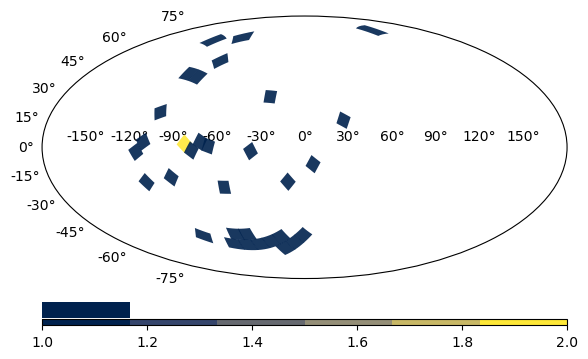

In [108]:
# use ztffields to plot the fields


if __name__ == "__main__":
    # Read the csv file as a Pandas dataframe
    fields_df = pd.read_csv("RWE_summary.csv")

    # and project to a focalplane shape | try using ccd or quadrant
    df = ztffields.radec_to_fieldid(fields_df, level="focalplane")

    # groupby field id
    fieldid_s = df.to_frame().groupby("fieldid").size()

    # - and limit to the main grid
    fieldid_s = fieldid_s[fieldid_s.index < 1000]

    # - and limit to the main grid
    # fieldid_s = fieldid_s[fieldid_s.index<1000]

    # Display
    fig = ztffields.skyplot_fields(fieldid_s, system="galactic")
    fig.savefig("plot_fields_galactic.pdf")

In [114]:
fieldid_s.index

Int64Index([ 400,  401,  402,  447,  448,  449,  450,  451,  497,  500,  501,
             515,  525,  561,  594,  608,  640,  686,  690,  695,  719,  757,
             765,  777,  795,  802,  803,  814,  822,  824,  831,  832, 1393,
            1394, 1395, 1441, 1442, 1443, 1444, 1445, 1446, 1447, 1491, 1493,
            1494, 1495, 1496, 1497, 1498, 1509, 1520, 1543, 1546, 1547, 1556,
            1561, 1590, 1604, 1607, 1637, 1639, 1653, 1684, 1688, 1693, 1718,
            1727, 1731, 1735, 1756, 1758, 1765, 1779, 1794, 1798, 1801, 1805,
            1806, 1812, 1813, 1818, 1827, 1829, 1835, 1836, 1837, 1838, 1846,
            1853, 1855, 1861, 1862],
           dtype='int64', name='fieldid')

In [261]:
fields_df

,fieldid,ra,dec
0,802,324.38344,54.95
1,501,15.74212,11.75
2,802,324.38344,54.95
3,831,340.00000,62.15
4,500,8.75787,11.75
5,561,81.12327,18.95
6,450,26.27176,4.55
7,451,33.28264,4.55
8,686,298.26936,33.35
9,640,300.75680,26.15


/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/ztffields/plotting.py:871: UserWarning: you are not using cartopy projection, issues may appear on the edge
  warnings.warn("you are not using cartopy projection, issues may appear on the edge")


NameError: name 'ax' is not defined

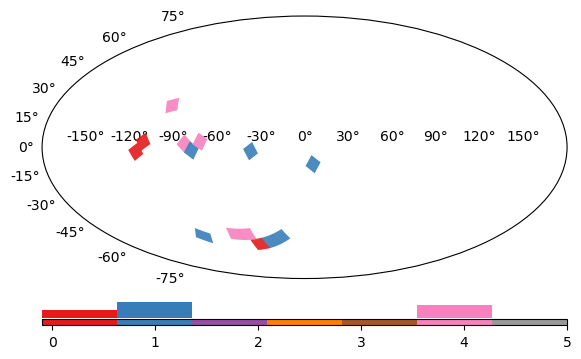

In [264]:
# Read the csv file as a Pandas dataframe
fields_df = pd.read_csv("RWE_summary_mydata.txt")


# and project to a focalplane shape | try using ccd or quadrant
df = ztffields.radec_to_fieldid(fields_df, level="focalplane")


# groupby field id
fieldid_s = df.to_frame().groupby("fieldid").size()


# - and limit to the main grid
fieldid_s = fieldid_s[fieldid_s.index < 1000]

# these are the three that we use in our analysis, so changing the color
fieldid_s[686] = 0
fieldid_s[640] = 0
fieldid_s[449] = 0


fieldid_s[802] = 4
fieldid_s[501] = 4
fieldid_s[831] = 4
fieldid_s[500] = 4
fieldid_s[798] = 4


# Display
fig = ztffields.skyplot_fields(
    fieldid_s, system="galactic", add_mw=False, cmap="Set1", vmin=-0.1, vmax=5
)  # hsv
# system=icrs is the default
ax.plot(np.linspace(-100, 100, 100), np.linspace(-100, 100, 100), size=10, zorder=10)
# plt.show()
# fig.savefig("plot_fields_galactic.pdf")

In [124]:
fieldid_s[fieldid_s.index < 1000]

fieldid
400    1
401    1
402    1
447    1
448    1
449    1
450    1
451    1
497    1
500    1
501    1
515    1
525    1
561    1
594    1
608    1
640    1
686    1
690    1
695    1
719    1
757    1
765    1
777    1
795    1
802    2
803    1
814    1
822    1
824    1
831    1
832    1
dtype: int64

In [119]:
fields_df

,fieldid,ra,dec
0,802,324.38344,54.95
1,501,15.74212,11.75
2,802,324.38344,54.95
3,831,340.00000,62.15
4,500,8.75787,11.75
5,561,81.12327,18.95
6,450,26.27176,4.55
7,451,33.28264,4.55
8,686,298.26936,33.35
9,640,300.75680,26.15


In [273]:
hdul = fits.open(
    "/lustre/lrspec/ZTF_data/2022/0820/ztf_20220820237546_000798_zr_c10_x_0002.fits.fz"
)

In [275]:
hdul[0].header

SIMPLE  =                    T / file does conform to FITS standard             
BITPIX  =                  -32 / number of bits per data pixel                  
NAXIS   =                    0 / number of data axes                            
EXTEND  =                    T / FITS dataset may contain extensions            
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
ORIGIN  = 'Zwicky Transient Facility' / Data origin                             
OBSERVER= 'ZTF Robotic Observing Software' / Observer                           
ROBOSOFT= '1.1 August 1, 2022' / Robotic software version                       
FITSSOFT= '1.1 August 1, 2022' / FITS software version                          
INSTRUME= 'ZTF/MOSAIC'         / Instrument name                                
DETECTOR= '        '           / Detector controller                            
DETSOFT = '        '        

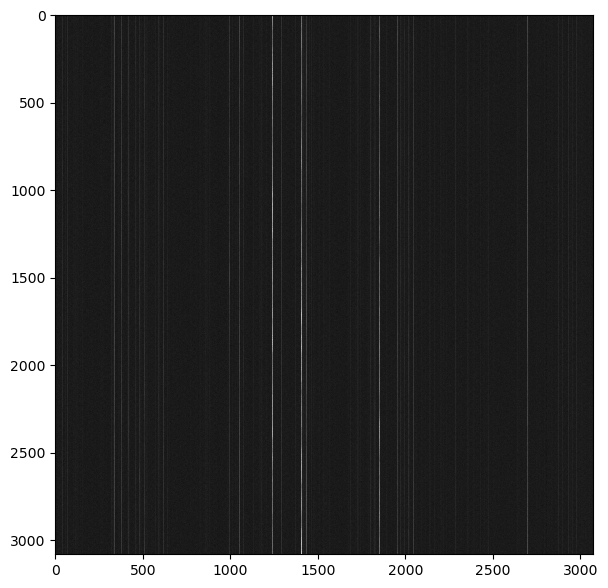

In [274]:
plt.imshow(np.sqrt(hdul[2].data))

In [271]:
hdul = fits.open(
    "/lustre/lrspec/ZTF_data/2022/20220808/ztf_20220808230833_000798_zr_c16_x.fits.fz"
)

In [65]:
# okay so now we should have a bunch of reduced dataframes

# Set the folder path where your DataFrames are stored
folder_path = "/lustre/lrspec/ZTF_data/science_extractions/1020"
direcname = "1020"
fpath = (
    "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
    + direcname
    + "_minus_extras/"
)


# List all the files in the folder
files = [
    f for f in os.listdir(folder_path) if f.endswith("sobelratio")
]  # Adjust this to your file format


# Step 3: Read all DataFrames and add the filename as a new column
dataframes = []
for f in files:
    df = pd.read_csv(os.path.join(folder_path, f))
    dataframes.append(df)

# Step 4: Concatenate all DataFrames into one
concatenated_df_sobel = pd.concat(dataframes, ignore_index=True)

# Display the concatenated DataFrame
concatenated_df_sobel

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio
0,0,34,34,ztf_20221020154120_000640_zi_c09_x_0017.,pos,173.500000,592.000000,6.0,4,22.759903
1,1,56,56,ztf_20221020154120_000640_zi_c09_x_0017.,pos,307.000000,592.000000,5.0,4,19.525473
2,2,71,71,ztf_20221020154120_000640_zi_c09_x_0017.,pos,399.076923,592.230769,13.0,4,12.377268
3,3,77,77,ztf_20221020154120_000640_zi_c09_x_0017.,pos,426.833333,592.166667,6.0,4,20.345509
4,4,85,85,ztf_20221020154120_000640_zi_c09_x_0017.,pos,463.000000,1751.833333,18.0,4,16.250433
...,...,...,...,...,...,...,...,...,...,...
614006,173,508,508,ztf_20221020138241_000686_zi_c15_x_0029.,both,2887.000000,523.000000,5.0,1,19.482388
614007,174,510,510,ztf_20221020138241_000686_zi_c15_x_0029.,both,2903.500000,523.250000,8.0,1,20.777689
614008,175,514,514,ztf_20221020138241_000686_zi_c15_x_0029.,both,2951.666667,523.333333,27.0,1,12.660818
614009,176,517,517,ztf_20221020138241_000686_zi_c15_x_0029.,both,2972.625000,523.375000,8.0,1,26.944208


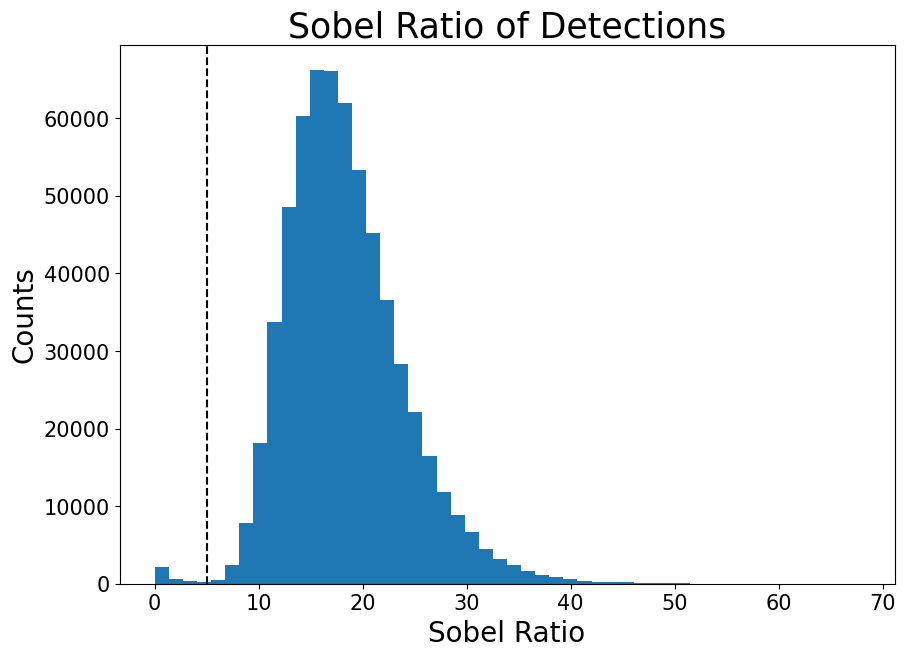

In [66]:
plt.hist(concatenated_df_sobel["sobel_ratio"], bins=50)
# plt.yscale('log')
plt.title("Sobel Ratio of Detections", fontsize=25)
plt.ylabel("Counts", fontsize=20)
plt.xlabel("Sobel Ratio", fontsize=20)
# plt.xlim(0,20)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.axvline(5, c="black", ls="dashed")
# plt.scatter(-13, 1)

In [68]:
# okay so now we should have a bunch of reduced dataframes

# Set the folder path where your DataFrames are stored
folder_path = "/lustre/lrspec/ZTF_data/science_extractions/1020"
direcname = "1020"
fpath = (
    "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
    + direcname
    + "_minus_extras/"
)


# List all the files in the folder
files = [
    f for f in os.listdir(folder_path) if f.endswith("snr")
]  # Adjust this to your file format


# Step 3: Read all DataFrames and add the filename as a new column
dataframes = []
for f in files:
    df = pd.read_csv(os.path.join(folder_path, f))
    dataframes.append(df)

# Step 4: Concatenate all DataFrames into one
concatenated_df_snr = pd.concat(dataframes, ignore_index=True)

# Display the concatenated DataFrame
concatenated_df_snr

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio,snr_center,snr_max,snr_min
0,0,0,3,3,ztf_20221020297847_000449_zr_c05_x_0006.,pos,627.166667,559.333333,6.0,4,12.891250,1.303873,1.792471,-1.921662
1,1,1,4,4,ztf_20221020297847_000449_zr_c05_x_0006.,pos,655.625000,1208.750000,8.0,4,12.620198,3.551599,3.661652,-3.093721
2,2,2,8,8,ztf_20221020297847_000449_zr_c05_x_0006.,pos,1834.833333,560.916667,12.0,4,7.786941,2.971391,2.971391,-1.201024
3,3,3,12,12,ztf_20221020297847_000449_zr_c05_x_0006.,pos,2343.333333,1209.500000,12.0,4,9.809223,3.095683,3.140310,-0.995967
4,4,4,25,25,ztf_20221020297847_000449_zr_c05_x_0006.,neg,647.000000,1209.928571,14.0,4,12.620198,-1.530615,3.552551,-3.001541
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
610898,263,263,551,551,ztf_20221020297847_000449_zr_c14_x_0026.,both,2923.142857,1320.428571,7.0,4,9.755448,0.476716,1.637385,-1.839140
610899,264,264,552,552,ztf_20221020297847_000449_zr_c14_x_0026.,both,2937.153846,1320.692308,13.0,4,11.997117,0.194553,0.760646,-1.656184
610900,265,265,554,554,ztf_20221020297847_000449_zr_c14_x_0026.,both,2951.500000,1321.416667,12.0,4,14.919274,-0.671413,0.720585,-1.495678
610901,266,266,555,555,ztf_20221020297847_000449_zr_c14_x_0026.,both,2952.000000,1326.000000,9.0,4,14.998910,-1.493181,0.719382,-1.493181


In [106]:
lessthan25 = concatenated_df_snr[concatenated_df_snr["snr_center"] < 25]

In [111]:
len(lessthan25[lessthan25["type"] == "both"])

304759

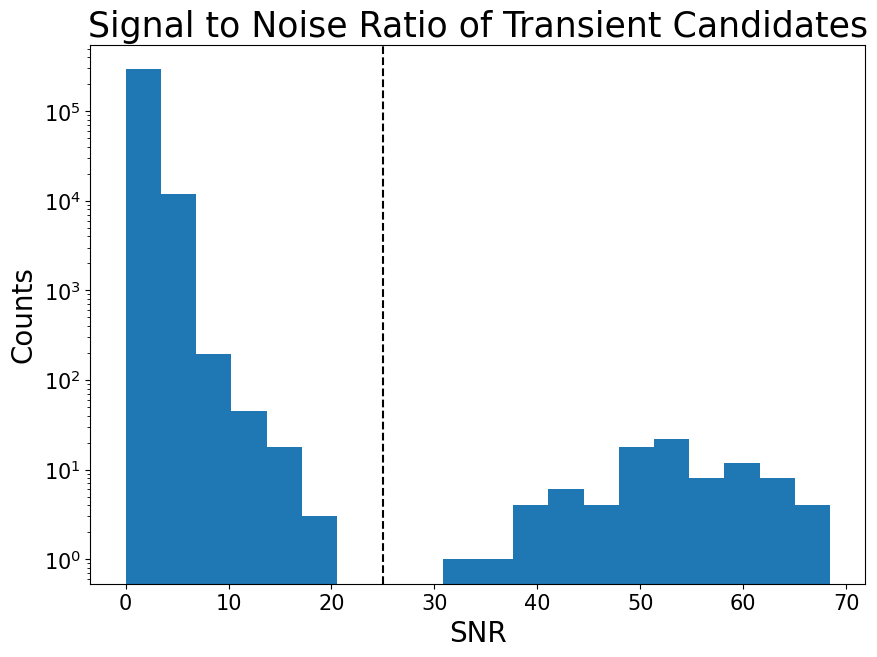

In [102]:
pos_df = concatenated_df_snr[concatenated_df_snr["type"] == "pos"]
neg_df = concatenated_df_snr[concatenated_df_snr["type"] == "neg"]

plt.hist(np.hstack((np.abs(pos_df["snr_max"]), np.abs(neg_df["snr_min"]))), bins=20)
plt.yscale("log")
plt.title("Signal to Noise Ratio of Transient Candidates", fontsize=25)
plt.ylabel("Counts", fontsize=20)
plt.xlabel("SNR", fontsize=20)
# plt.xlim(0,20)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.axvline(25, c="black", ls="dashed")
# plt.scatter(-13, 1)

In [121]:
concatenated_df_snr.sort_values("snr_max").iloc[67000]

Unnamed: 0.3                                           246
Unnamed: 0.2                                           246
Unnamed: 0.1                                          1008
Unnamed: 0                                            1008
filename          ztf_20221020148032_000686_zg_c14_x_0027.
type                                                   neg
row_from_nn                                    1845.980769
col_from_nn                                    1684.519231
detection_size                                        52.0
quadrant                                                 1
sobel_ratio                                       9.470841
snr_center                                       -1.801385
snr_max                                           0.601425
snr_min                                          -2.046484
Name: 161359, dtype: object

In [100]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/review_findings_functions.py'>

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020138241_000686_zi_c16_x_0026.fits.fz


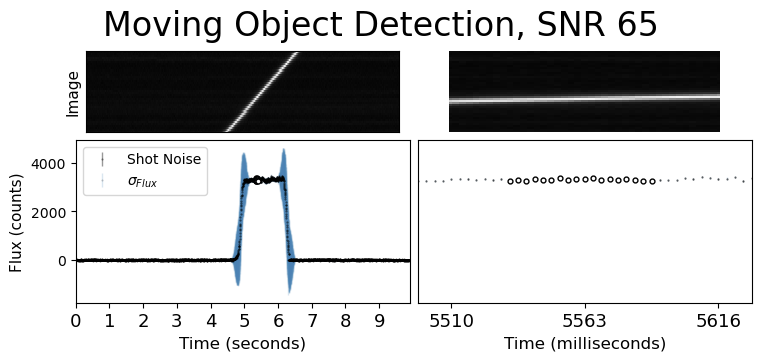

In [255]:
rff.plot_time_series_again_aperture(
    pos_df, 475161, "1020", 2, True, "Moving Object Detection, SNR 65"
)

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020157697_000640_zi_c16_x_0009.fits.fz


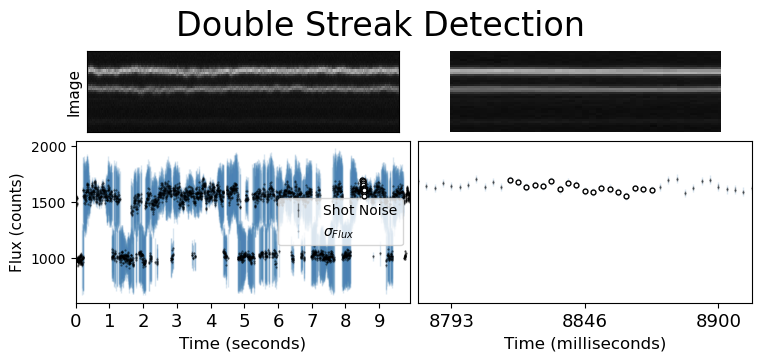

In [256]:
# for index in concatenated_df_snr[concatenated_df_snr['snr_max']<12].sort_values('snr_max')[610659:].index:
rff.plot_time_series_again_aperture(
    concatenated_df_snr[concatenated_df_snr["snr_max"] < 12],
    25286,
    "1020",
    2,
    True,
    "Double Streak Detection",
)

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


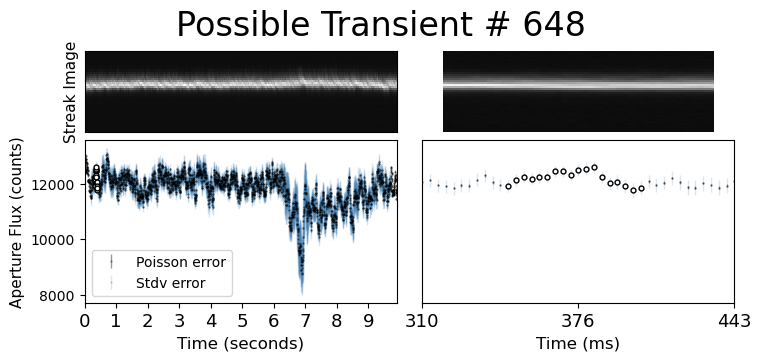

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


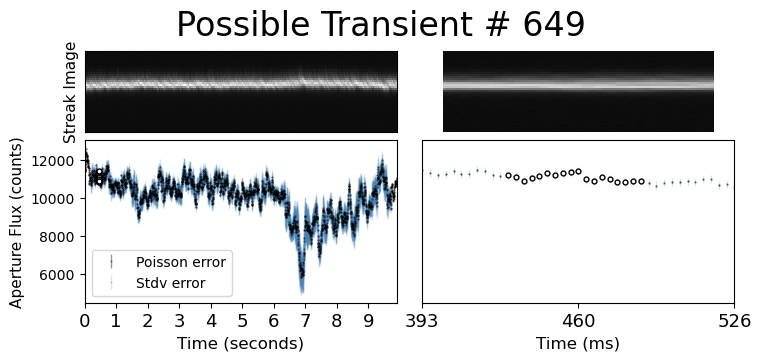

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


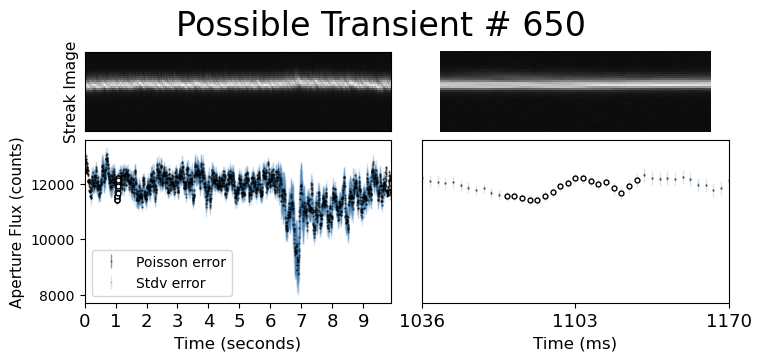

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


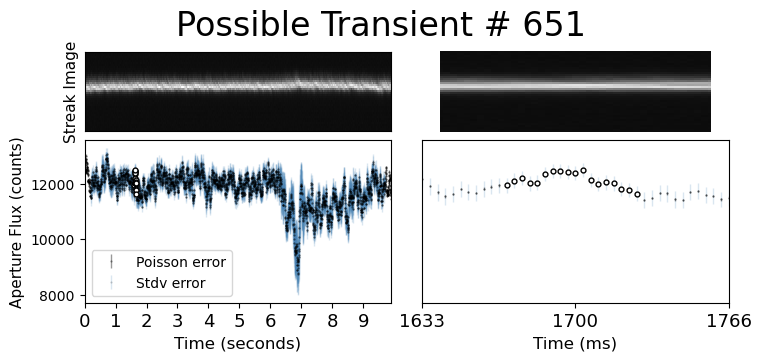

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


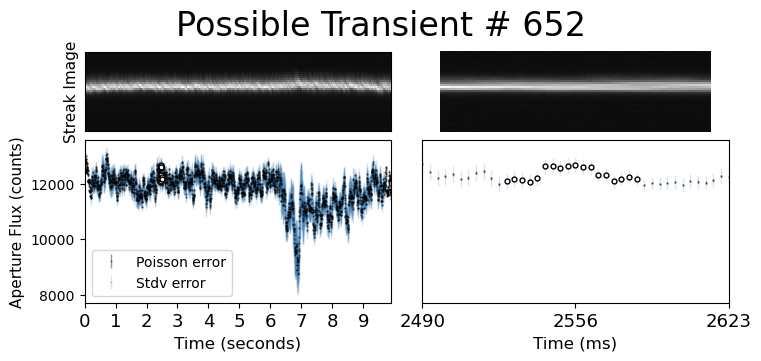

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


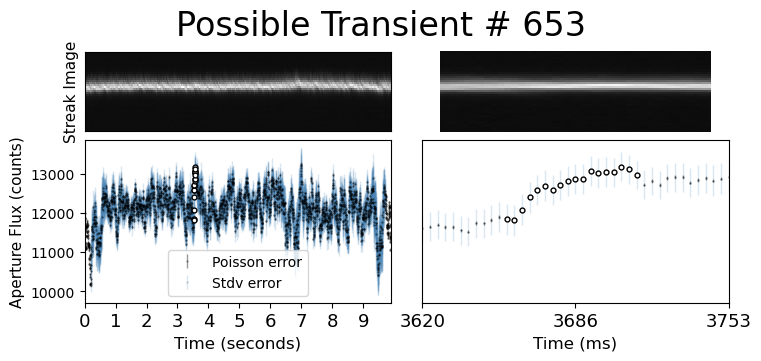

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


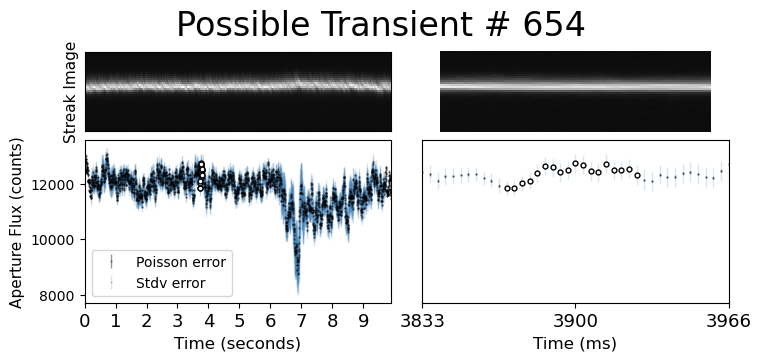

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


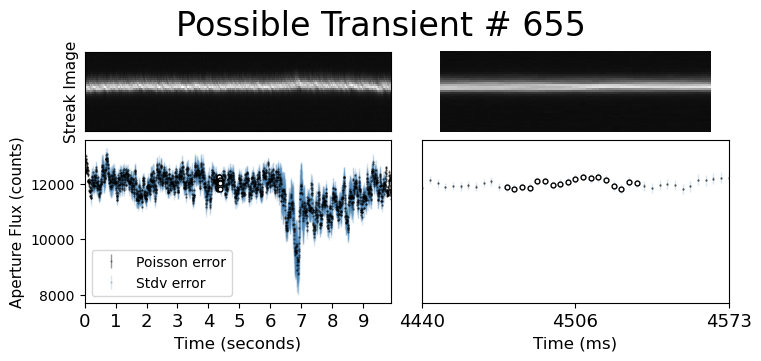

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


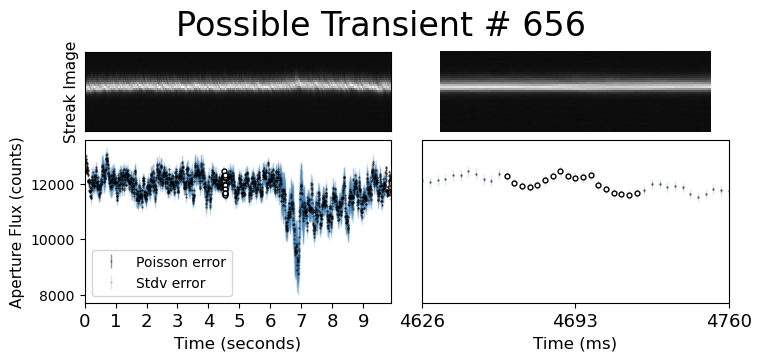

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


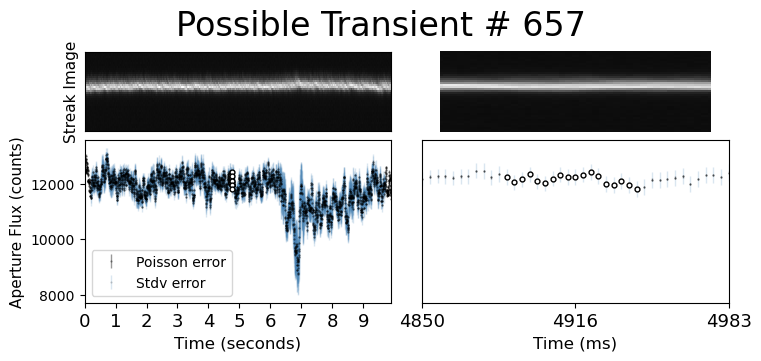

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


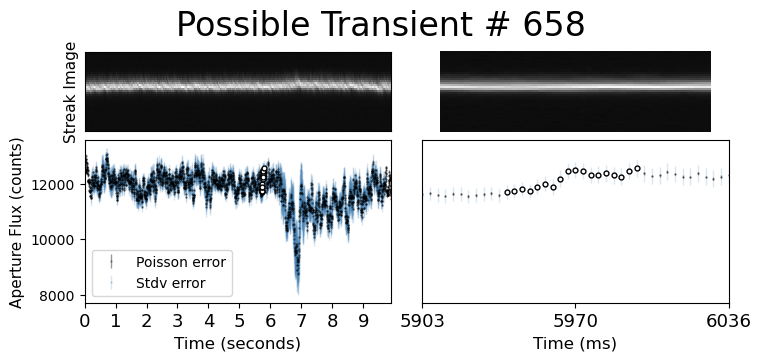

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


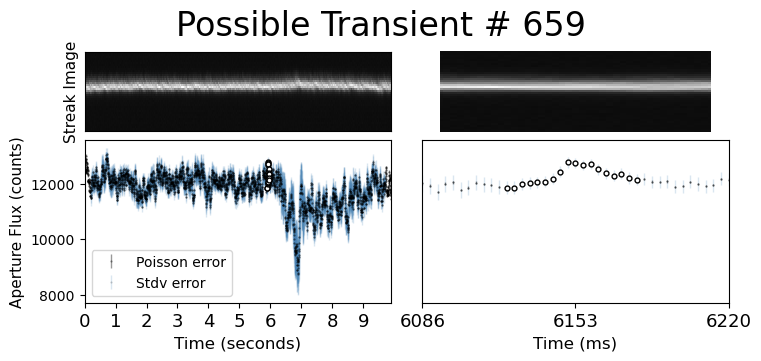

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


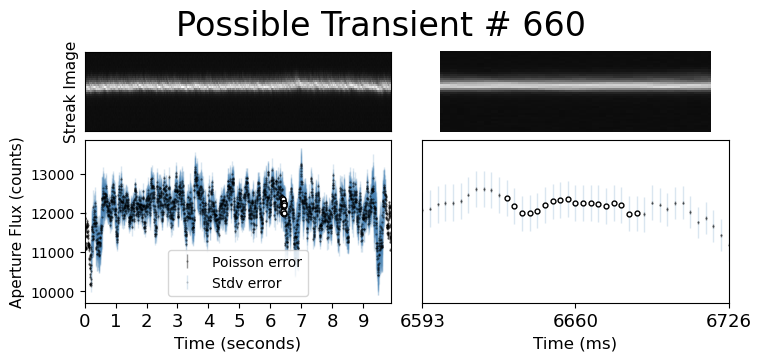

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


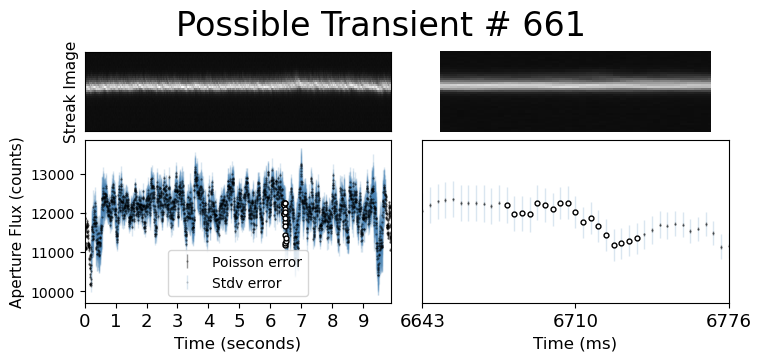

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


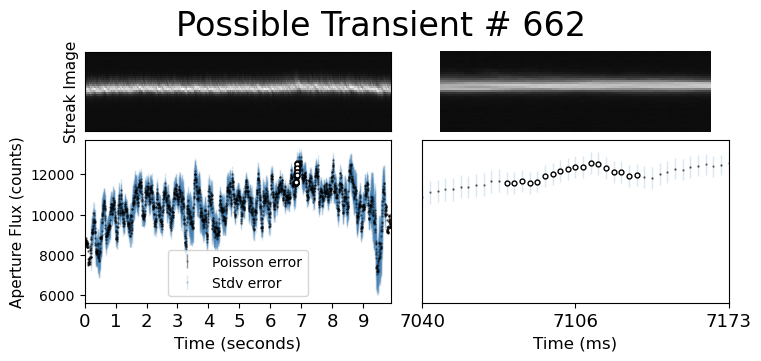

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


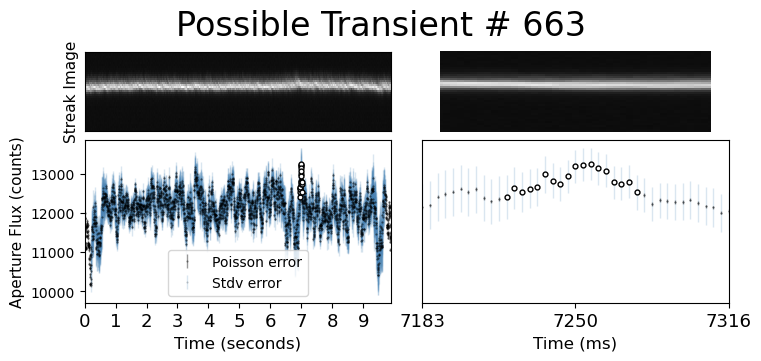

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


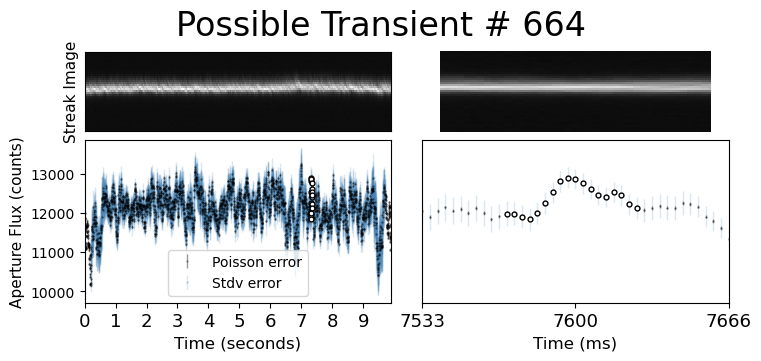

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


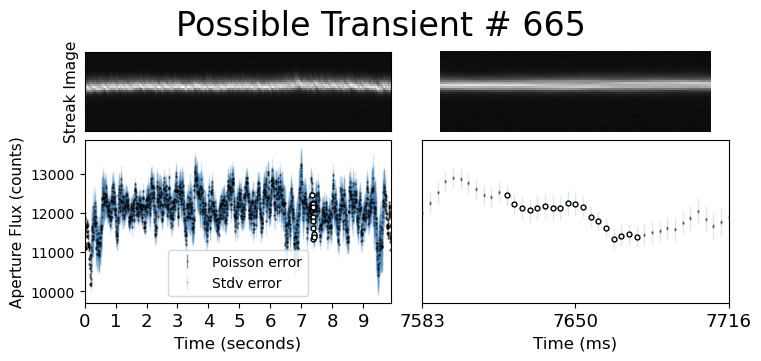

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


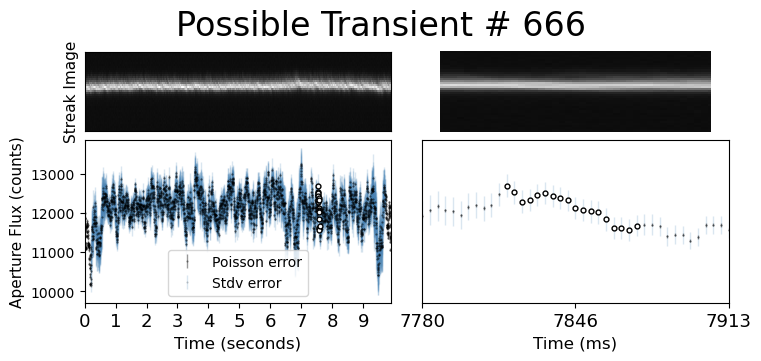

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


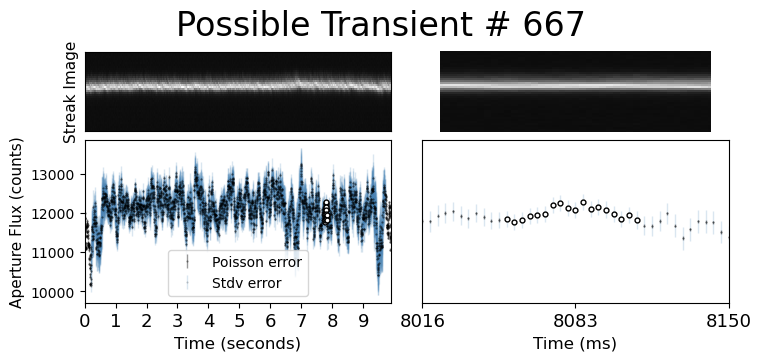

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


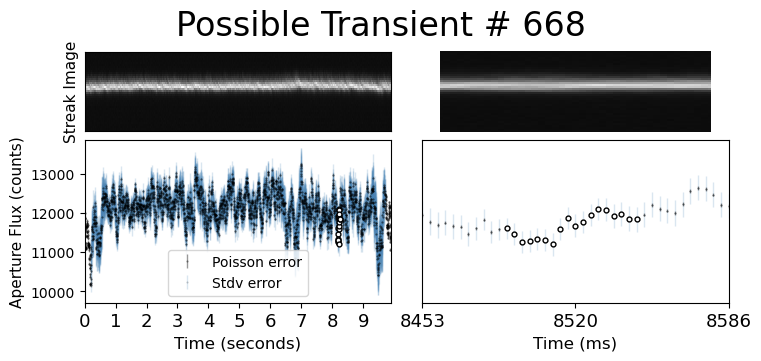

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


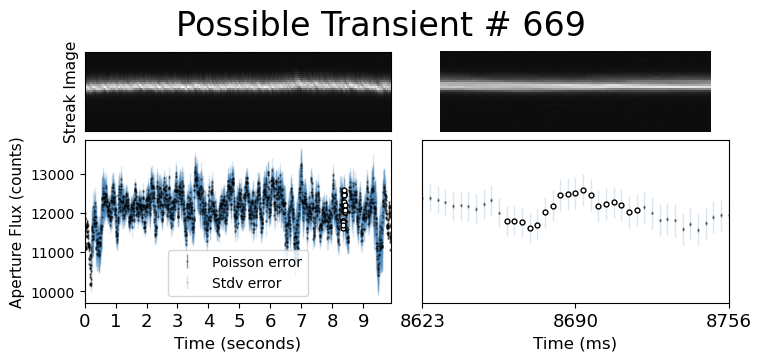

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


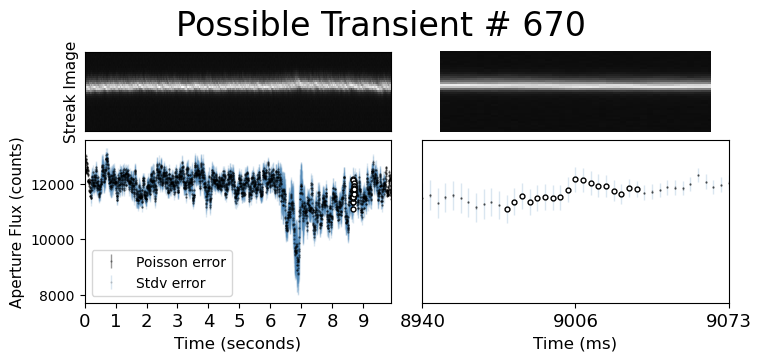

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


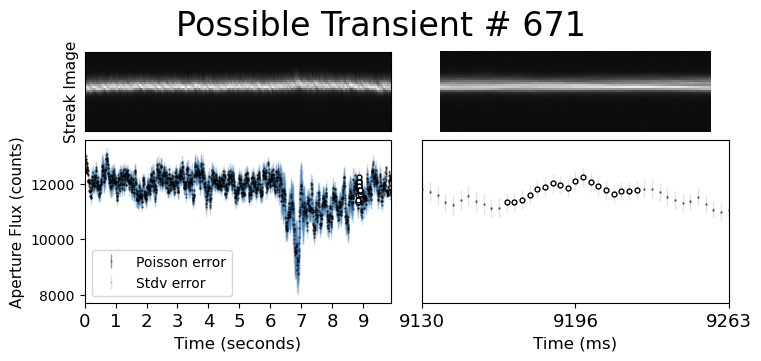

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


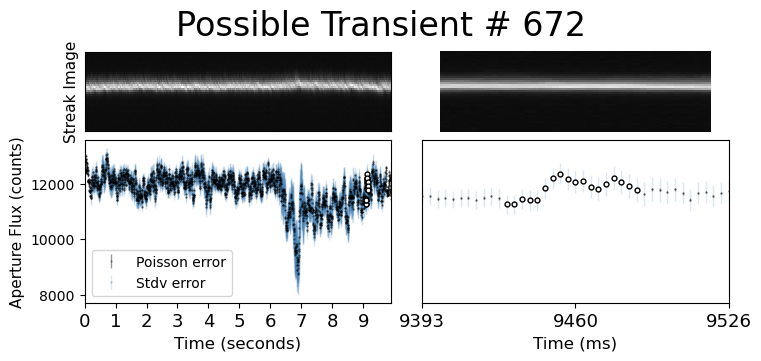

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


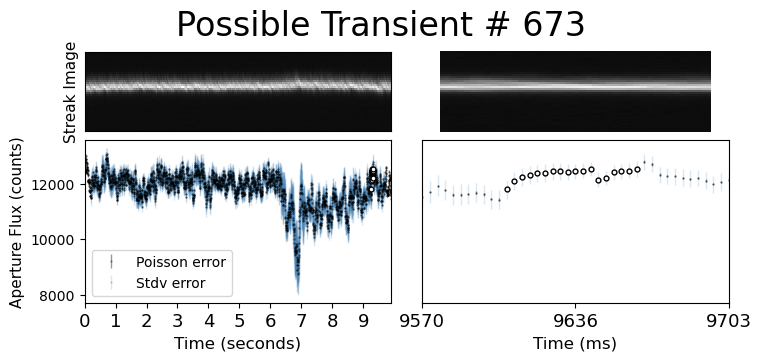

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


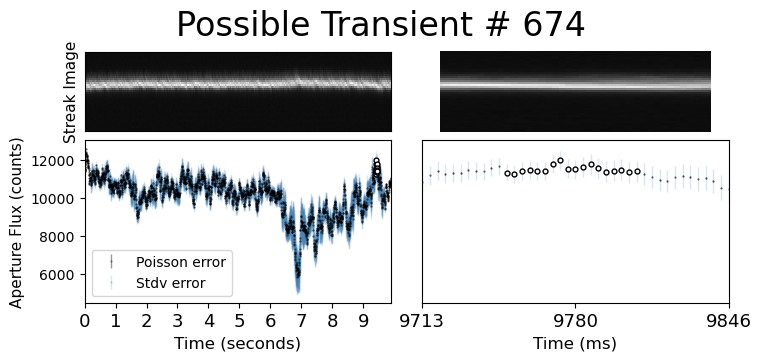

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


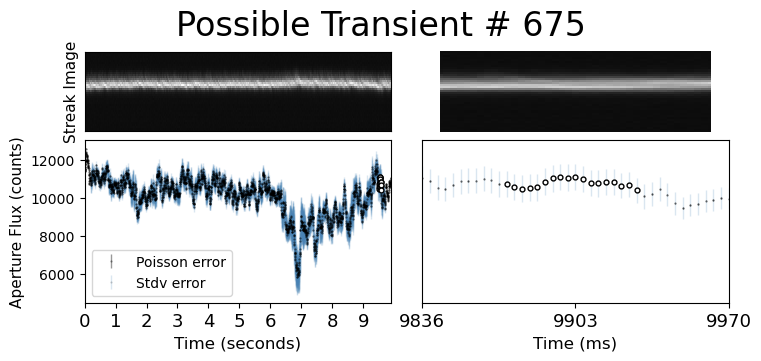

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


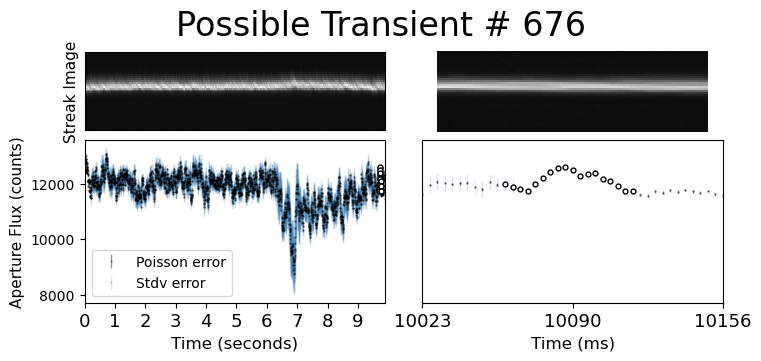

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


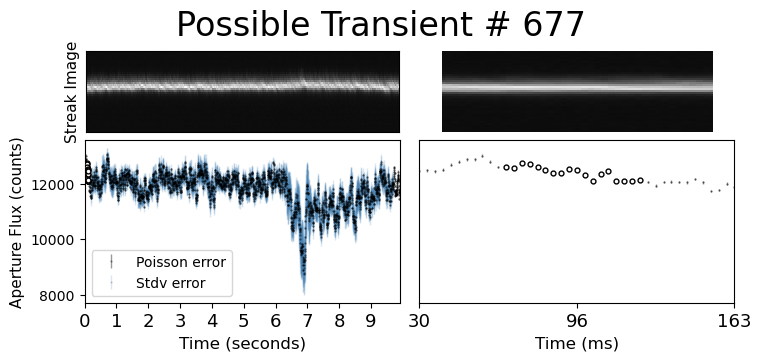

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


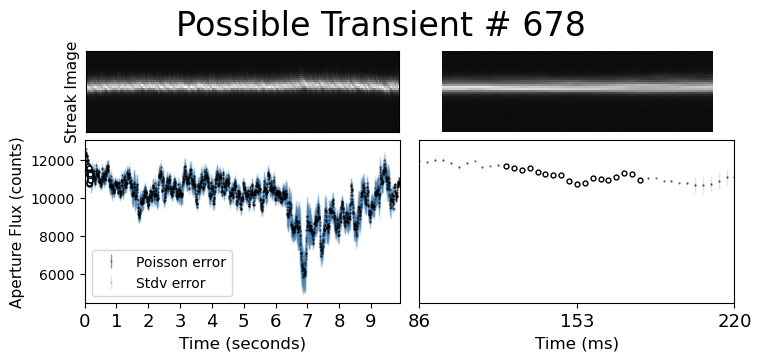

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


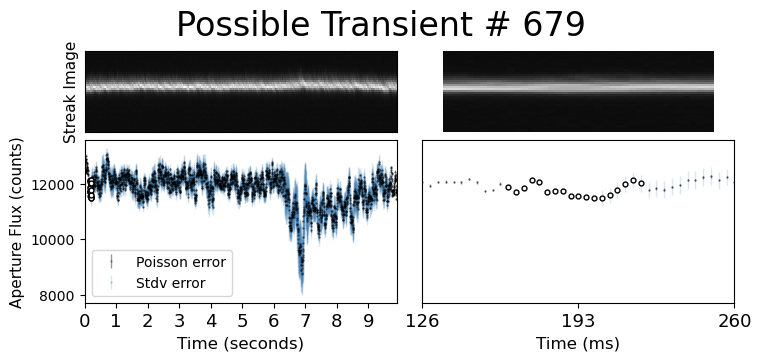

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


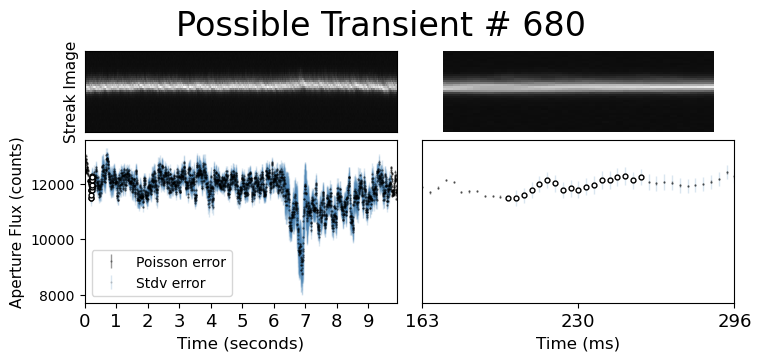

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


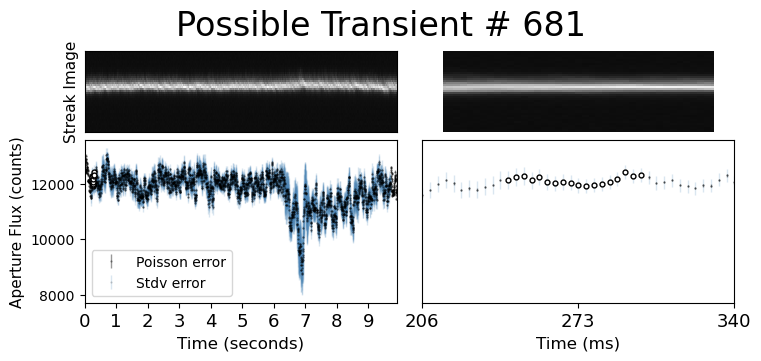

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


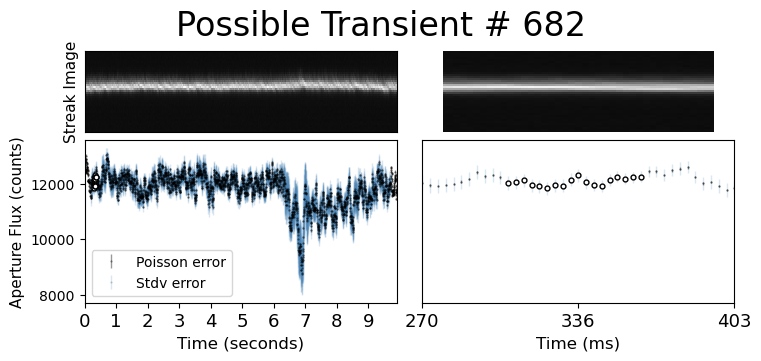

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


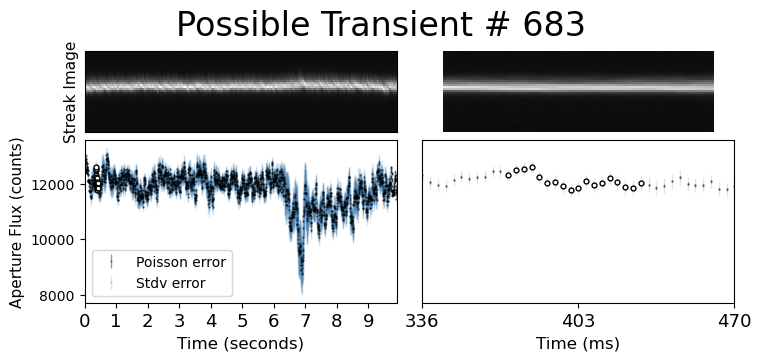

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


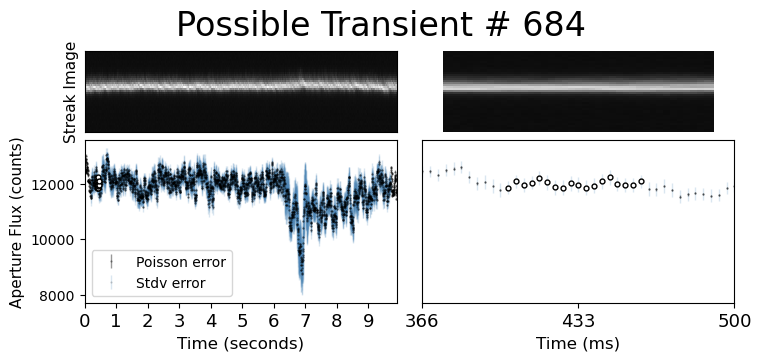

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


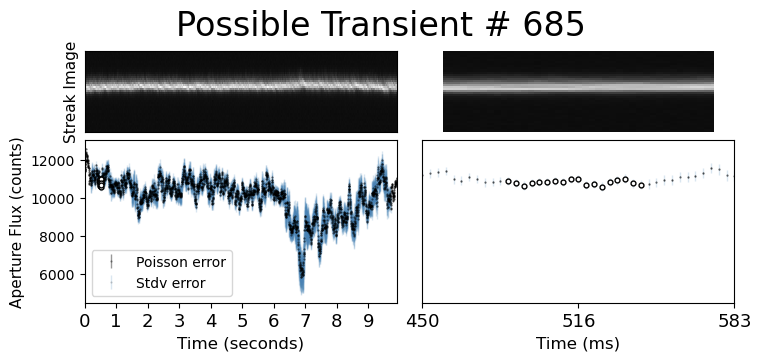

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0016.fits.fz


KeyboardInterrupt: 

In [214]:
# for index in concatenated_df_snr[concatenated_df_snr['filename']=='ztf_20221020294271_000449_zr_c13_x_0016.'].index:
#     plot_time_series_again_aperture_tracking(concatenated_df_snr,index,half_aperture=2, tracking=False, plot_tracking=False)

In [257]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/review_findings_functions.py'>

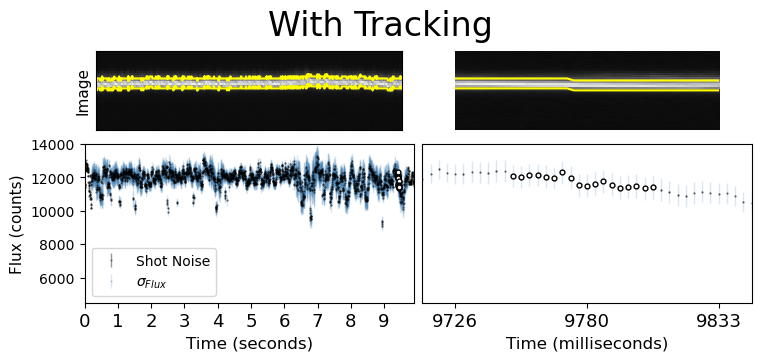

In [258]:
rff.plot_time_series_again_aperture(
    concatenated_df_snr,
    674,
    half_aperture=2,
    tracking=True,
    plot_tracking=True,
    title="With Tracking",
    ylims=(4500, 14000),
)